## Setup

In [1]:
import os, sys, glob
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

WORK = "/kaggle/working"
DATA_DIR = f"{WORK}/data"
OUT_DIR = f"{WORK}/outputs"
RESULTS_DIR = f"{WORK}/results"
for d in (DATA_DIR, OUT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

def find(name):
    hits = sorted(glob.glob(f"{WORK}/**/{name}", recursive=True)) + \
           sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True))
    if not hits:
        raise FileNotFoundError(f"{name} not found: attach the dataset/notebook that makes it (Add Input)")
    if len(hits) > 1:
        print(f"note: {len(hits)} copies of {name}, using {hits[0]}")
    return hits[0]

RAW_CSV = find("afri_med_qa_15k_v2.4_phase_2_15275.csv")

HF_USER = "Tresor26"
def hub_id(run_name):
    return f"{HF_USER}/clinicmate-{run_name}"

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login
login(token=UserSecretsClient().get_secret("HF_TOKEN"))

REPO = "/kaggle/temp/ClinicMate"
if not os.path.exists(REPO):
    !git clone -q https://github.com/Tresorshingiro/ClinicMate.git {REPO}
else:
    !git -C {REPO} pull -q
sys.path.append(REPO)

import random, numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED)

## GPU packages

In [2]:
!pip install -q peft bitsandbytes evaluate rouge_score bert_score
import torch; torch.manual_seed(42)
print(torch.cuda.device_count(), torch.cuda.get_device_name(0))   # should print "1 Tesla T4"

import importlib.metadata as md                                   # copy this output into requirements.txt
for p in ["torch", "transformers", "peft", "accelerate", "bitsandbytes", "datasets",
          "evaluate", "sentence-transformers", "scikit-learn", "pandas"]:
    print(f"{p}=={md.version(p)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.9 MB/s eta 0:00:00
1 Tesla T4
torch==2.11.0+cu128
transformers==5.16.1
peft==0.20.0
accelerate==1.14.0
bitsandbytes==0.50.2
datasets==4.8.5
evaluate==0.4.6
sentence-transformers==5.7.0
scikit-learn==1.6.1
pandas==2.3.3


## Imports

In [3]:
import json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
                          TrainingArguments, Trainer, DataCollatorForSeq2Seq)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from src.prompts import build_messages, build_target

## Experiment config

Change **only** `RUN` between runs. Order: `debug_0.5b` (interactive) → `E2` → `E1` → `E4` → `E3` (each as Save & Run All).

In [4]:
Q05, Q15 = "Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"

DEFAULTS = dict(lora_r=16, lora_alpha=32, lora_dropout=0.05, lr=2e-4, epochs=3, max_len=1024,
                batch_size=4, grad_accum=4,                  # effective batch 16
                train_file="train", val_file="val", max_train=None)
RUNS = {
    "debug_0.5b":           dict(base_model=Q05, epochs=1, max_train=300),
    "E2_qwen1.5b_r16":      dict(base_model=Q15),
    "E1_qwen0.5b_r16":      dict(base_model=Q05),
    "E4_qwen1.5b_official": dict(base_model=Q15, train_file="official_train", val_file="official_val"),
    "E3_qwen1.5b_r8":       dict(base_model=Q15, lora_r=8, lora_alpha=16),
}

RUN = "E3_qwen1.5b_r8"                                   # <- the only line you change between runs
CFG = {"run_name": RUN, **DEFAULTS, **RUNS[RUN]}
RUN_DIR = f"{OUT_DIR}/{CFG['run_name']}"
print(json.dumps(CFG, indent=2))

{
  "run_name": "E3_qwen1.5b_r8",
  "lora_r": 8,
  "lora_alpha": 16,
  "lora_dropout": 0.05,
  "lr": 0.0002,
  "epochs": 3,
  "max_len": 1024,
  "batch_size": 4,
  "grad_accum": 4,
  "train_file": "train",
  "val_file": "val",
  "max_train": null,
  "base_model": "Qwen/Qwen2.5-1.5B-Instruct"
}


## Tokenize: prompt + target, label masking

In [5]:
tok = AutoTokenizer.from_pretrained(CFG["base_model"])
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

def load_split(name, is_train=False):
    d = pd.read_json(find(f"{name}.jsonl"), lines=True)
    if is_train and CFG["max_train"]:
        d = d.sample(CFG["max_train"], random_state=42)
    return Dataset.from_pandas(d, preserve_index=False)

def tokenize(ex):
    prompt = tok.apply_chat_template(build_messages(ex), tokenize=False, add_generation_prompt=True)
    target = build_target(ex) + tok.eos_token          # Qwen eos = <|im_end|>, ends the turn
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    t_ids = tok(target, add_special_tokens=False)["input_ids"]
    input_ids = (p_ids + t_ids)[: CFG["max_len"]]
    labels = ([-100] * len(p_ids) + t_ids)[: CFG["max_len"]]   # -100 = ignored by the loss
    return {"input_ids": input_ids, "attention_mask": [1] * len(input_ids), "labels": labels}

train_ds = load_split(CFG["train_file"], is_train=True)
val_ds = load_split(CFG["val_file"])
cols = train_ds.column_names
train_ds = train_ds.map(tokenize, remove_columns=cols)
val_ds = val_ds.map(tokenize, remove_columns=cols)
train_ds = train_ds.filter(lambda e: any(l != -100 for l in e["labels"]))   # avoid NaN loss
val_ds = val_ds.filter(lambda e: any(l != -100 for l in e["labels"]))
lens = [len(x) for x in train_ds["input_ids"]]
print(train_ds, "\ntoken length p50/p95/max:", np.percentile(lens, 50), np.percentile(lens, 95), max(lens))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Map:   0%|          | 0/3663 [00:00<?, ? examples/s]

Map:   0%|          | 0/523 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3663 [00:00<?, ? examples/s]

Filter:   0%|          | 0/523 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 3663
}) 
token length p50/p95/max: 155.0 247.89999999999964 486


## 4-bit base model + LoRA adapters (QLoRA)

In [6]:
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(CFG["base_model"], quantization_config=bnb, device_map="auto")
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
model.config.use_cache = False
lora = LoraConfig(r=CFG["lora_r"], lora_alpha=CFG["lora_alpha"], lora_dropout=CFG["lora_dropout"],
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
                  bias="none", task_type="CAUSAL_LM")
model = get_peft_model(model, lora)
model.print_trainable_parameters()          # record this number in the report

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 9,232,384 || all params: 1,552,946,688 || trainable%: 0.5945


## Train

In [7]:
args = TrainingArguments(
    output_dir=RUN_DIR,
    num_train_epochs=CFG["epochs"],
    per_device_train_batch_size=CFG["batch_size"],
    per_device_eval_batch_size=CFG["batch_size"],
    gradient_accumulation_steps=CFG["grad_accum"],
    learning_rate=CFG["lr"], lr_scheduler_type="cosine", warmup_steps=0.03,
    fp16=True,                                  # T4 has no bf16
    gradient_checkpointing=True,
    logging_steps=10,
    eval_strategy="steps", eval_steps=50,       # ~230 optimiser steps per epoch on the full train set
    save_strategy="steps", save_steps=50, save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="eval_loss",
    train_sampling_strategy="group_by_length",
    report_to="none", seed=42,
)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100))
t0 = time.time()
trainer.train()
print(f"training took {(time.time() - t0) / 60:.1f} min")
print("best checkpoint:", trainer.state.best_model_checkpoint, trainer.state.best_metric)

Step,Training Loss,Validation Loss
50,1.293055,1.043507
100,1.304071,1.019437
150,1.232049,0.978362
200,1.224123,0.941682
250,0.931021,0.913091
300,0.635599,0.933440
350,0.812502,0.929828
400,0.563326,0.924232
450,0.624297,0.917133
500,0.362954,0.976582


training took 47.6 min
best checkpoint: /kaggle/working/outputs/E3_qwen1.5b_r8/checkpoint-250 0.9130905866622925


## Save adapter, training log and loss curve

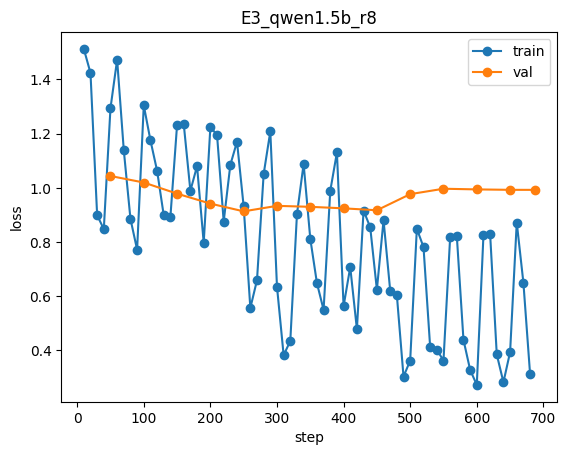

In [8]:
trainer.model.save_pretrained(f"{RUN_DIR}/adapter"); tok.save_pretrained(f"{RUN_DIR}/adapter")
json.dump({"cfg": CFG, "log_history": trainer.state.log_history},
          open(f"{RESULTS_DIR}/{CFG['run_name']}_train_log.json", "w"), indent=2)
h = trainer.state.log_history
tr = [(x["step"], x["loss"]) for x in h if "loss" in x]
va = [(x["step"], x["eval_loss"]) for x in h if "eval_loss" in x]
plt.plot(*zip(*tr), marker="o", label="train")
if va: plt.plot(*zip(*va), marker="o", label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title(CFG["run_name"])
plt.savefig(f"{RESULTS_DIR}/{CFG['run_name']}_loss.png", dpi=150, bbox_inches="tight"); plt.show()

## Push adapter + log + loss plot to a private Hub repo

In [9]:
from huggingface_hub import HfApi
api = HfApi()
api.create_repo(hub_id(CFG["run_name"]), private=True, exist_ok=True)
api.upload_folder(folder_path=f"{RUN_DIR}/adapter", repo_id=hub_id(CFG["run_name"]))
for f in [f"{CFG['run_name']}_train_log.json", f"{CFG['run_name']}_loss.png"]:
    api.upload_file(path_or_fileobj=f"{RESULTS_DIR}/{f}", path_in_repo=f, repo_id=hub_id(CFG["run_name"]))
print("pushed to", hub_id(CFG["run_name"]))

pushed to Tresor26/clinicmate-E3_qwen1.5b_r8


## Sanity check: one MCQ and one SAQ answer

In [10]:
from src.evaluation import generate_answers
model.eval(); model.config.use_cache = True
val = pd.read_json(find(f"{CFG['val_file']}.jsonl"), lines=True)
for qt in ["mcq", "saq"]:
    ex = val[val.qtype == qt].iloc[0].to_dict()
    print(f"===== {qt} =====\nQ: {ex['question']}\n")
    print("MODEL:", generate_answers(model, tok, [build_messages(ex)])[0], "\n")
    print("GOLD: ", build_target(ex), "\n")

===== mcq =====
Q: Which of the following is the correct order of the epidermal layers, fromdeepest to most superficial?

MODEL: Answer: C 

GOLD:  Answer: A 

===== saq =====
Q: How does the prevalence of tuberculosis vary across African countries?

MODEL: Tuberculosis (TB) is endemic in many African countries, with varying rates depending on factors such as poverty, overcrowding, and access to healthcare. 

GOLD:  Tuberculosis prevalence varies across the African countries, with high burden countries including South Africa, Nigeria, and the Democratic Republic of the Congo. 

